In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df= pd.read_csv('data.csv')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6819 entries, 0 to 6818
Data columns (total 96 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   Bankrupt?                                                 6819 non-null   int64  
 1    ROA(C) before interest and depreciation before interest  6819 non-null   float64
 2    ROA(A) before interest and % after tax                   6819 non-null   float64
 3    ROA(B) before interest and depreciation after tax        6819 non-null   float64
 4    Operating Gross Margin                                   6819 non-null   float64
 5    Realized Sales Gross Margin                              6819 non-null   float64
 6    Operating Profit Rate                                    6819 non-null   float64
 7    Pre-tax net Interest Rate                                6819 non-null   float64
 8    After-tax net Int

In [ ]:
from scipy import stats

In [ ]:
from sklearn import preprocessing

In [ ]:
df=df.to_numpy()

In [ ]:
np.shape(df)

(6819, 96)

In [ ]:
df

array([[1.        , 0.37059426, 0.42438945, ..., 0.56405011, 1.        ,
        0.01646874],
       [1.        , 0.46429094, 0.53821413, ..., 0.57017495, 1.        ,
        0.02079431],
       [1.        , 0.42607127, 0.49901875, ..., 0.56370608, 1.        ,
        0.01647411],
       ...,
       [0.        , 0.47272461, 0.533744  , ..., 0.5651584 , 1.        ,
        0.09764874],
       [0.        , 0.50626432, 0.5599106 , ..., 0.56530151, 1.        ,
        0.04400945],
       [0.        , 0.49305319, 0.57010467, ..., 0.56516694, 1.        ,
        0.23390224]])

In [ ]:
df=np.transpose(df)

In [ ]:
y = np.transpose(df[0])
X = np.transpose(df[1:])

In [ ]:
np.shape(X),np.shape(y)

((6819, 95), (6819,))

In [ ]:
#Count the features that have no difference at all in all data
np.shape(X)[1]-np.count_nonzero(np.std(X,axis=0))

1

In [ ]:
#Find the index of feature which have no difference at all
np.min(np.std(X,axis=0)), np.where(np.std(X,axis=0)==0), np.argmin(np.std(X,axis=0))

(0.0, (array([93]),), 93)

In [ ]:
check_feature_name_with_sd_0=[]

In [ ]:
for i in range(np.shape(np.where(np.std(X,axis=0)==0))[0]):
  print(pd.read_csv('data.csv').columns.tolist()[(list(np.where(np.std(X,axis=0)==0)[i])[0])])

 Interest Coverage Ratio (Interest expense to EBIT)


In [ ]:
X=np.delete(X,list(np.where(np.std(X,axis=0)==0)),axis=1)

In [ ]:
#Count the features that have no difference at all in all data after deleting the data
np.shape(X)[1]-np.count_nonzero(np.std(X,axis=0))

0

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
X_train, X_train_val, y_train, y_train_val = train_test_split(X_train, y_train, test_size=0.15, random_state=0)

In [ ]:
np.shape(X_train),np.shape(y_train),np.shape(X_test),np.shape(y_test)

((4636, 94), (4636,), (1364, 94), (1364,))

In [ ]:
np.shape(X_train_val),np.shape(y_train_val)

((819, 94), (819,))

In [ ]:
np.shape(np.mean(X_train,axis=0))

(94,)

In [ ]:
mean=np.copy(np.mean(X_train,axis=0))
std=np.copy(np.std(X_train,axis=0))

In [ ]:
X_train_rescale=(X_train-mean)/(std)

In [ ]:
X_train_rescale

array([[ 1.90296242,  1.75119366,  1.86826578, ..., -0.04482293,
        -0.0121836 , -0.42214359],
       [ 0.6281232 ,  0.28436509,  0.77600121, ..., -0.0377838 ,
         0.03174293, -0.38983898],
       [-0.09873029, -0.31695914, -0.10257863, ..., -0.02571204,
         0.08874173, -0.36849753],
       ...,
       [ 0.01346857,  0.23656108,  0.0457645 , ..., -0.03814377,
         0.02972356, -0.33827418],
       [-0.49061327, -0.26663912, -0.43193569, ..., -0.03723269,
         0.03479245, -0.30907101],
       [ 0.35087819,  0.39506914,  0.47489998, ..., -0.04117001,
         0.0118357 , -0.29664792]])

In [ ]:
#Check all value is not NaN, -infity or infinity
np.isfinite(X_train_rescale).all()

True

In [ ]:
X_train_new_rescale=np.copy(X_train_rescale[(abs(X_train_rescale)<3.5).all(axis=1)])
#Even y_train_new_rescale is called y_train_new_rescale, we did not rescale it.
#We just remove the outliers according to X_train
y_train_new_rescale=np.copy(y_train[(abs(X_train_rescale)<3.5).all(axis=1)])

In [ ]:
np.shape(X_train_new_rescale), np.shape(y_train_new_rescale)

((3716, 94), (3716,))

In [ ]:
import sklearn
from sklearn import preprocessing

In [ ]:
scaler = preprocessing.StandardScaler().fit(X_train_new_rescale)

In [ ]:
X_train_new_rescale=scaler.transform(X_train_new_rescale)

In [ ]:
X_train_new_rescale

array([[ 2.22267222,  2.15271734,  2.2175063 , ..., -0.13707927,
        -0.10647741, -0.60464602],
       [ 0.69800339,  0.29926856,  0.88484896, ..., -0.07956124,
         0.10246805, -0.5447885 ],
       [-0.50092305,  0.1795203 , -0.26466226, ..., -0.11282918,
        -0.01263509, -0.71777716],
       ...,
       [ 0.27307975,  0.30244772,  0.45283959, ..., -0.07624096,
         0.11318652,  0.1867281 ],
       [-0.63997129, -0.39696691, -0.58893862, ..., -0.07505807,
         0.11697369, -0.39513275],
       [ 0.36642682,  0.43915149,  0.5174794 , ..., -0.10723062,
         0.00777523, -0.37211388]])

In [ ]:
#Check all value is not NaN, -infity or infinity
np.isfinite(X_train_new_rescale).all()

True

In [ ]:
y_train_new_rescale

array([0., 0., 0., ..., 0., 0., 0.])

In [ ]:
#Show that not all the value are 0 in y_train_new_rescale
np.squeeze(np.argwhere(y_train_new_rescale==1))

array([   3,   31,   66,   95,  166,  176,  192,  280,  318,  366,  401,
        428,  451,  452,  467,  517,  537,  722,  738,  755,  763,  777,
        793,  812,  822,  840,  918,  926,  938, 1026, 1054, 1077, 1127,
       1138, 1146, 1188, 1267, 1300, 1385, 1389, 1414, 1450, 1547, 1616,
       1635, 1694, 1743, 1750, 1794, 1891, 1912, 1995, 2045, 2081, 2143,
       2150, 2167, 2178, 2236, 2317, 2363, 2455, 2504, 2535, 2592, 2601,
       2625, 2632, 2657, 2661, 2673, 2897, 2905, 2908, 2925, 2930, 2995,
       3029, 3053, 3072, 3164, 3252, 3308, 3374, 3387, 3407, 3424, 3437,
       3477, 3483, 3489, 3497, 3503, 3525, 3686, 3707])

In [ ]:
#Same rescaling in test dataset
X_test_rescale=(X_test-mean)/(std)
y_test_rescale=np.copy(y_test)

In [ ]:
#Same as the training dataset, apply twice the standardization
X_test_rescale=scaler.transform(X_test_rescale)

In [ ]:
#Check all value is not NaN, -infity or infinity
np.isfinite(X_test_rescale).all()

True

In [ ]:
#Same rescaling in validation set
X_train_val_rescale=(X_train_val-mean)/(std)
y_train_val_rescale=np.copy(y_train_val)

In [ ]:
#Same as the training dataset, apply twice the standardization
X_train_val_rescale=scaler.transform(X_train_val_rescale)

In [ ]:
#Check all value is not NaN, -infity or infinity
np.isfinite(X_train_val_rescale).all()

True

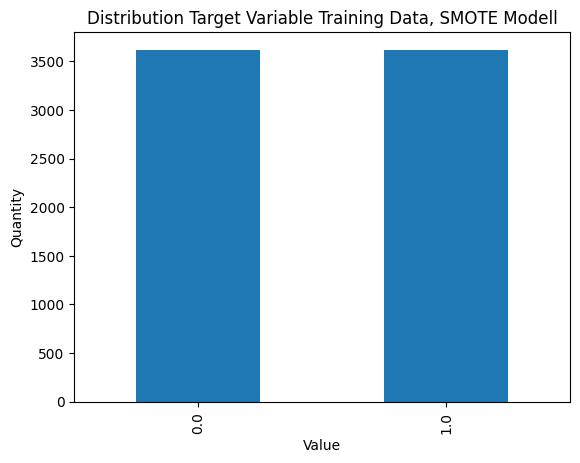

In [ ]:
#Oversampling: SMOTE Model
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train_new_rescale, y_train_new_rescale)
y_resampled_series = pd.Series(y_resampled)

value_counts = y_resampled_series.value_counts()
value_counts.plot(kind="bar")
plt.title("Distribution Target Variable Training Data, SMOTE Modell")
plt.ylabel("Quantity")
plt.xlabel("Value")
plt.show()

In [ ]:
np.shape(X_resampled),np.shape(y_resampled),np.shape(X_test_rescale),np.shape(y_test_rescale)

((7240, 94), (7240,), (1364, 94), (1364,))

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout

In [ ]:
model = Sequential([
    Dense(256, activation='sigmoid', input_shape=(X_resampled.shape[1],)),
    Dropout(0.20),
    Dense(32, activation='sigmoid'),
    Dropout(0.30),
    Dense(16, activation='relu'),
    Dropout(0.30),
    Dense(8, activation='softmax'),
    Dropout(0.30),
    Dense(4, activation='relu'),
    Dropout(0.30),
    Dense(2, activation='sigmoid'),
    Dropout(0.20),
    Dense(1, activation='sigmoid')
])

In [ ]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [ ]:
history=model.fit(X_resampled, y_resampled, epochs=500, batch_size=150,\
                   validation_data = (X_train_val_rescale, y_train_val_rescale))

Epoch 1/500
49/49 [==============================] - 4s 17ms/step - loss: 0.7114 - accuracy: 0.4985 - val_loss: 0.5228 - val_accuracy: 0.9731
Epoch 2/500
49/49 [==============================] - 0s 7ms/step - loss: 0.6741 - accuracy: 0.5162 - val_loss: 0.5426 - val_accuracy: 0.9731
Epoch 3/500
49/49 [==============================] - 0s 6ms/step - loss: 0.6485 - accuracy: 0.6159 - val_loss: 0.5467 - val_accuracy: 0.8608
Epoch 4/500
49/49 [==============================] - 0s 6ms/step - loss: 0.6292 - accuracy: 0.6622 - val_loss: 0.5352 - val_accuracy: 0.8779
Epoch 5/500
49/49 [==============================] - 0s 6ms/step - loss: 0.6083 - accuracy: 0.6960 - val_loss: 0.5214 - val_accuracy: 0.8669
Epoch 6/500
49/49 [==============================] - 0s 7ms/step - loss: 0.5921 - accuracy: 0.7298 - val_loss: 0.5102 - val_accuracy: 0.8681
Epoch 7/500
49/49 [==============================] - 0s 6ms/step - loss: 0.5725 - accuracy: 0.7604 - val_loss: 0.4992 - val_accuracy: 0.8523
Epoch 8/500


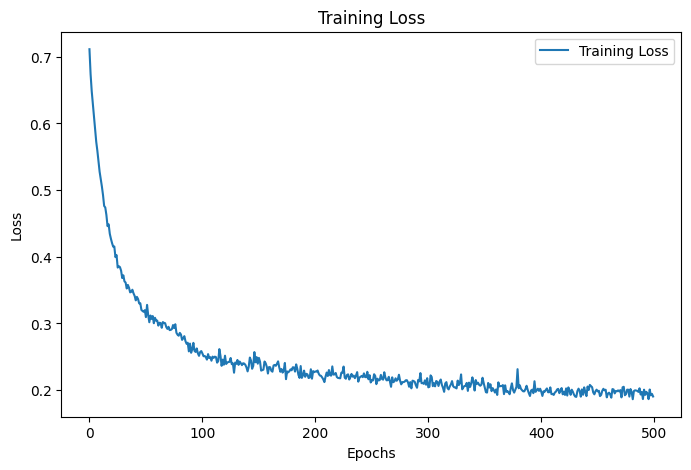

In [ ]:
# Plot loss
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

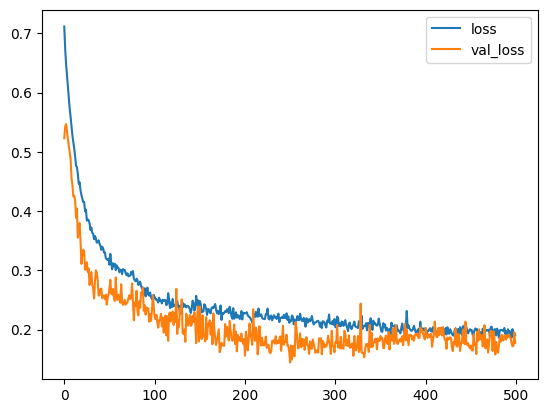

In [ ]:
plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.legend()
plt.show()

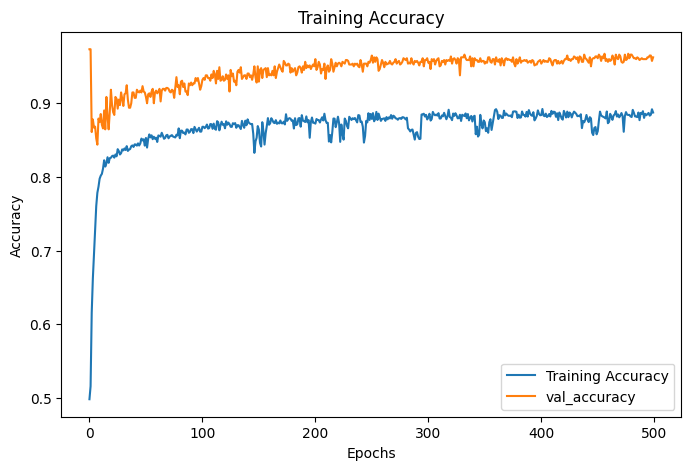

In [ ]:
# Plot accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.title('Training Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
# Prediction on test data
predictions = model.predict(X_test_rescale)
predicted_classes = np.round(predictions).flatten()

# Assuming binary classification (0 or 1)
accuracy = np.mean(predicted_classes == y_test)
print(f"Test Accuracy: {accuracy*100}%")

43/43 [==============================] - 1s 7ms/step
Test Accuracy: 95.60117302052787%


In [ ]:
# import evaluation tools
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve, auc

In [ ]:
# evaluate result
print("Accuracy:",accuracy_score(y_test, predicted_classes, normalize=True, sample_weight=None))
print("Confusion Matrix:", '\n', confusion_matrix(y_test, predicted_classes))

Accuracy: 0.9560117302052786
Confusion Matrix: 
 [[1295   23]
 [  37    9]]


In [ ]:
print("Non-bankrupted(value=0): ",np.count_nonzero(y_test==0))
print("Bankrupted(value=1): ",np.count_nonzero(y_test))

Non-bankrupted(value=0):  1318
Bankrupted(value=1):  46


In [ ]:
test_confusion_matrix=np.copy(confusion_matrix(y_test, predicted_classes))

In [ ]:
print("Recall=TP/(TP+FN)= ",test_confusion_matrix[1,1]/(test_confusion_matrix[1,1]+test_confusion_matrix[1,0]))

Recall=TP/(TP+FN)=  0.1956521739130435


In [ ]:
#prob of bankrupted (value=1)
predictions

array([[0.00408569],
       [0.00409921],
       [0.00405666],
       ...,
       [0.00408627],
       [0.00405272],
       [0.0040543 ]], dtype=float32)

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, predictions)

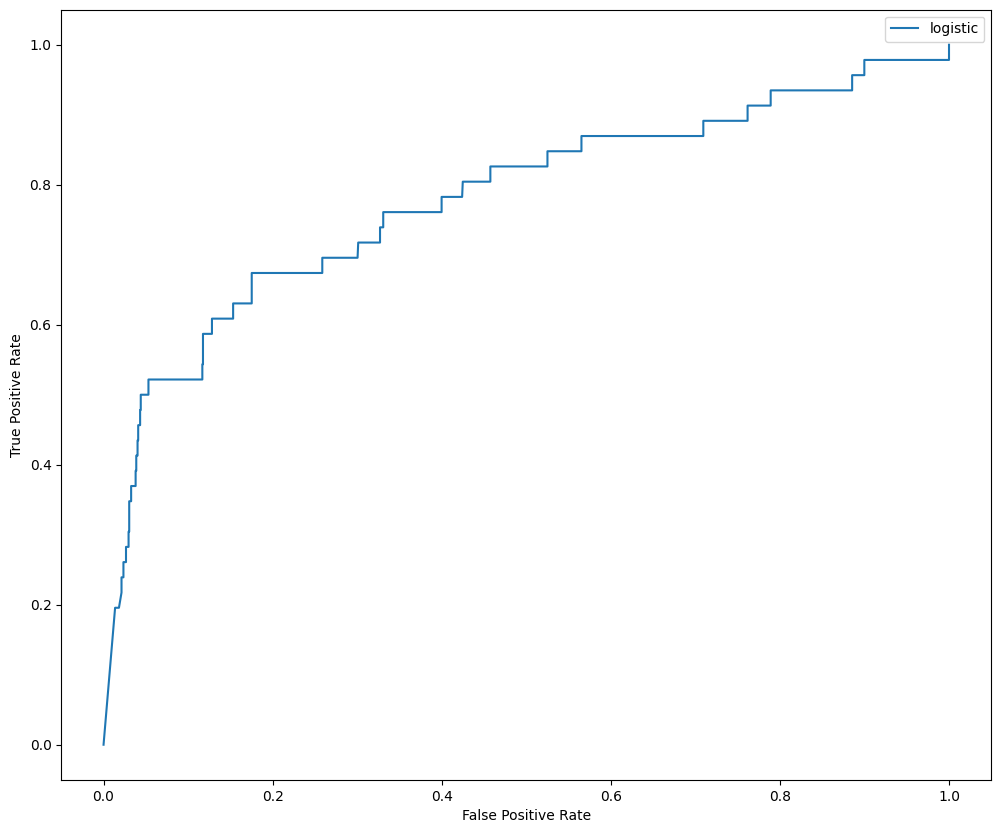

In [ ]:
# Plot the ROC curves
plt.figure(figsize=(12, 10))
plt.plot(fpr, tpr, label="logistic")
plt.legend()
plt.ylabel("True Positive Rate")
plt.xlabel("False Positive Rate")
plt.show()

In [ ]:
from sklearn.metrics import auc

# Get AUC
auc = auc(fpr, tpr)

# Print results
pd.DataFrame({"Model":['Artificial Neural Network'], "AUC":[auc]})

,Model,AUC
0,Artificial Neural Network,0.778419


In [ ]:
#Investor perspective: Highly aware if the company would go bankrupt
#Set the prediction threshold to be 0.15, if the probability of
#going bankrupt is larger than 15%, then it would be predictied as True.

In [ ]:
investor_prediction=np.copy(predictions)

In [ ]:
investor_predict_bankeuptcy=[]

In [ ]:
for i in range(np.shape(investor_prediction)[0]):
  if investor_prediction[i]<=0.15:
    investor_predict_bankeuptcy.append(0)
  else:
    investor_predict_bankeuptcy.append(1)

In [ ]:
print(investor_predict_bankeuptcy)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

In [ ]:
print(f'This is confusion matrix for decision tree in investor perspective: \n{confusion_matrix(y_test, investor_predict_bankeuptcy)}')

This is confusion matrix for decision tree in investor perspective: 
[[1294   24]
 [  37    9]]


In [ ]:
investor_confusion_matrix=np.copy(confusion_matrix(y_test, investor_predict_bankeuptcy))

In [ ]:
#We set cost as getting FP is 1, while FN is 10
#FP means investors would falsely identify a non-bankrupt company as bankrupt
#FN means investors would falsely identify a bankrupt company as non-bankrupt
#The cost of FN should be much higher than FP.
#Higher the cost, the worse it is.

In [ ]:
print("Cost:",investor_confusion_matrix[0,1]+investor_confusion_matrix[1,0]*10)

Cost: 394


In [ ]:
cost=investor_confusion_matrix[0,1]+investor_confusion_matrix[1,0]*10

In [ ]:
#We set gain of TP is 5, while TN is 0.5
#TP means investors would correctly identify a bankrupt company as bankrupt
#TN means investors would correctly identify a non-bankrupt company as non-bankrupt
#The gain of TP should be higher than TN
#In investors perspective, FP and FN should be more aware
#The value of cost should be larger than the value of gain
#because even it is non-bankrupt, it does not mean investor
#would earn a lot in that company
#Higher the gain, the better it is.

In [ ]:
print("Gain:", investor_confusion_matrix[0,0]*0.1+investor_confusion_matrix[1,1]*5)

Gain: 174.4


In [ ]:
#Net cost is used to calculate the cost including the earning when we correctly identify
#Net cost=cost-gain
#Higher the net cost, the worse it is.

In [ ]:
gain=investor_confusion_matrix[0,0]*0.1+investor_confusion_matrix[1,1]*5

In [ ]:
print("Net cost:", cost-gain)

Net cost: 219.6


In [ ]:
print("Recall=TP/(TP+FN)= ",investor_confusion_matrix[1,1]/(investor_confusion_matrix[1,1]+investor_confusion_matrix[1,0]))

Recall=TP/(TP+FN)=  0.1956521739130435
